# Figure — Neutralization-associated LASV GPC antibody specificity

Publication-style figure assembly for the neutralization section.

**Panels**
- **A** — Significant positive-neutralization GPC peptides mapped to LASV Josiah GPC.
- **B** — Coordinate-aligned LASV/Mammarenavirus neutralization-associated peptide sequences.
- **C** — Neutralization in GP2-region-reactive vs nonreactive survivors, with adjusted effect estimates.
- **D** — GPC positional/structural annotation track for the neutralization-associated region and literature-supported neutralizing-antibody footprints.

This notebook is deliberately figure-focused. It expects outputs from the preceding neutralization analysis (`screen`, `positive_hits`, `mapped_hits`, and survivor-level metadata). Where possible, it can reconstruct them from the standard project files.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

from scipy.stats import mannwhitneyu
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

# ---------- paths ----------
LONG_FILE = Path('./output_files/lassa_df_filtered_peps_reactive_3_proteins.csv')
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
REF_FASTA = Path('./ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta')

OUTDIR = Path('./output_figures/Fig_neutralization_GPC')
OUTDIR.mkdir(parents=True, exist_ok=True)




# ---------- color-blind-friendly palette ----------
SURVIVOR_COLOR = '#C23B6E'
BLUE = '#0072B2'
GREEN = '#009E73'
PURPLE = '#CC79A7'
GRAY = '#6E6E6E'
LIGHT_GRAY = '#D9D9D9'

# ---------- publication style ----------
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 8.5,
    'axes.labelsize': 9.5,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

# Josiah boundaries used throughout the project
SSP_END = 58
GP1_END = 259


## 1. Load/reconstruct the neutralization screen

The figure uses only **positive-direction neutralization associations**:
`FDR_screen < 0.05` and `delta_median_neut > 0`.


In [2]:
df = pd.read_csv(LONG_FILE)
meta = pd.read_csv(META_FILE)

meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')

baseline = (
    meta.sort_values(['participant_id','collection_date'])
        .groupby('participant_id', as_index=False)
        .first()
)

survivors = baseline.loc[baseline['Category'].eq('S')].copy()

keep_meta = [
    'sample_id','participant_id','Neut_Percent','GP_Calc_Conc',
    'age_years','sex','years_since_discharge'
]
survivor_meta = survivors[keep_meta].copy()
survivor_meta['sample_id'] = survivor_meta['sample_id'].astype(str)

# LASV GPC
lasv_gpc = df.loc[
    df['species'].astype(str).str.contains('lassa', case=False, na=False)
    & df['protein_std'].eq('glycoprotein')
].copy()

lasv_gpc['individual'] = lasv_gpc['individual'].astype(str)

lasv_neut = lasv_gpc.merge(
    survivor_meta,
    left_on='individual',
    right_on='sample_id',
    how='inner'
)

lasv_neut = lasv_neut.loc[lasv_neut['Neut_Percent'].notna()].copy()
lasv_neut['sex_model'] = lasv_neut['sex'].astype(object)

rows = []
for peptide, g in lasv_neut.groupby('peptide'):
    g = g.drop_duplicates('individual')
    pos = g.loc[g['reactive'].astype(bool), 'Neut_Percent'].dropna()
    neg = g.loc[~g['reactive'].astype(bool), 'Neut_Percent'].dropna()
    if len(pos) < 3 or len(neg) < 3:
        continue
    _, p = mannwhitneyu(pos, neg, alternative='two-sided')
    r0 = g.iloc[0]
    rows.append({
        'peptide': peptide,
        'sequence': r0['sequence'],
        'species': r0['species'],
        'accession': r0.get('accession', np.nan),
        'n_reactive': len(pos),
        'n_nonreactive': len(neg),
        'median_neut_reactive': pos.median(),
        'median_neut_nonreactive': neg.median(),
        'delta_median_neut': pos.median() - neg.median(),
        'p_screen': p
    })

screen = pd.DataFrame(rows)
screen['FDR_screen'] = multipletests(screen['p_screen'], method='fdr_bh')[1]

positive_hits = (
    screen.loc[
        (screen['FDR_screen'] < 0.05)
        & (screen['delta_median_neut'] > 0)
    ]
    .sort_values('FDR_screen')
    .copy()
)

print('LASV GPC peptides tested:', len(screen))
print('Positive neutralization-associated hits:', len(positive_hits))
display(positive_hits)


LASV GPC peptides tested: 16
Positive neutralization-associated hits: 11


/tmp/ipykernel_3325091/2375421548.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  meta['collection_date'] = pd.to_datetime(meta['collection_date'], errors='coerce')


,peptide,sequence,species,accession,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,p_screen,FDR_screen
5,AZI96412.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,Mammarenavirus lassaense,AZI96412.1,30,88,86.760952,65.507722,21.253230,1.157934e-07,0.000002
3,AZI96059.1|precursor|Mammarenavirus_lassaense|...,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,Mammarenavirus lassaense,AZI96059.1,32,86,86.349969,66.403041,19.946928,1.811954e-06,0.000010
6,AZI96476.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,Mammarenavirus lassaense,AZI96476.1,35,83,86.166650,67.722491,18.444158,1.239494e-06,0.000010
9,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,Mammarenavirus lassaense,AZI96488.1,35,83,85.841573,67.242783,18.598790,4.309758e-06,0.000017
0,AHC95553.1|precursor|Mammarenavirus_lassaense|...,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,Mammarenavirus lassaense,AHC95553.1,24,94,87.618931,68.569823,19.049108,6.488869e-06,0.000021
2,ANH09740.1|precursor|Mammarenavirus_lassaense|...,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,Mammarenavirus lassaense,ANH09740.1,47,71,84.984398,64.203796,20.780602,2.038991e-05,0.000047
15,XBA96065.1|precursor|Mammarenavirus_lassaense|...,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,Mammarenavirus lassaense,XBA96065.1,50,68,84.484379,63.994275,20.490105,2.003584e-05,0.000047
4,AZI96059.1|precursor|Mammarenavirus_lassaense|...,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,Mammarenavirus lassaense,AZI96059.1,18,100,87.908520,69.534578,18.373942,3.426302e-05,0.000069
10,AZI96488.1|precursor|Mammarenavirus_lassaense|...,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,Mammarenavirus lassaense,AZI96488.1,23,95,86.988617,69.676952,17.311664,6.758745e-05,0.000120
7,AZI96476.1|precursor|Mammarenavirus_lassaense|...,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,Mammarenavirus lassaense,AZI96476.1,22,96,87.618931,69.993715,17.625216,1.955781e-04,0.000313


## 2. Josiah GPC reference and full-peptide mapping

In [3]:
records = list(SeqIO.parse(REF_FASTA, 'fasta'))

for i, rec in enumerate(records):
    print(i, rec.id, len(rec.seq), rec.description)

gpc_candidates = [
    r for r in records
    if ('glycoprotein' in r.description.lower()
        or 'gpc' in r.description.lower()
        or 'precursor' in r.description.lower())
]

if len(gpc_candidates) != 1:
    raise ValueError(
        'Could not uniquely identify GPC. Inspect records above and set gpc_ref manually.'
    )

gpc_ref = str(gpc_candidates[0].seq)

aligner = PairwiseAligner()
aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5


0 sp|O09705|L_LASSJ 2218 sp|O09705|L_LASSJ RNA-directed RNA polymerase L OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=L PE=3 SV=1
1 sp|O73557|Z_LASSJ 99 sp|O73557|Z_LASSJ RING finger protein Z OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=Z PE=1 SV=4
2 sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1
3 sp|P13699|NCAP_LASSJ 569 sp|P13699|NCAP_LASSJ Nucleoprotein OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=N PE=1 SV=1


In [4]:
def align_full_peptide_to_reference(peptide, reference, aligner):
    peptide = str(peptide).upper()
    reference = str(reference).upper()

    alns = aligner.align(reference, peptide)
    if len(alns) == 0:
        return None

    aln = alns[0]
    ref_blocks, pep_blocks = aln.aligned
    if len(ref_blocks) == 0:
        return None

    pep_to_ref = {}
    for (r0,r1),(p0,p1) in zip(ref_blocks, pep_blocks):
        block_len = min(r1-r0, p1-p0)
        for off in range(block_len):
            pep_to_ref[p0+off] = r0+off+1

    if not pep_to_ref:
        return None

    first_p = min(pep_to_ref)
    first_r = pep_to_ref[first_p]
    full_start = first_r - first_p
    full_end = full_start + len(peptide) - 1

    return {
        'full_start': int(full_start),
        'full_end': int(full_end),
        'pep_to_ref': pep_to_ref,
        'score': aln.score
    }

mapped = []
for _, row in positive_hits.iterrows():
    res = align_full_peptide_to_reference(row['sequence'], gpc_ref, aligner)
    if res is None:
        continue
    mapped.append({**row.to_dict(), **res})

mapped_hits = (
    pd.DataFrame(mapped)
      .sort_values(['full_start','full_end'])
      .reset_index(drop=True)
)

display(
    mapped_hits[
        ['peptide','full_start','full_end','delta_median_neut','FDR_screen','sequence']
    ]
)


,peptide,full_start,full_end,delta_median_neut,FDR_screen,sequence
0,XBA96065.1|precursor|Mammarenavirus_lassaense|...,300,345,20.490105,0.000047,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI
1,ANH09740.1|precursor|Mammarenavirus_lassaense|...,301,346,20.780602,0.000047,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN
2,AZI96059.1|precursor|Mammarenavirus_lassaense|...,346,391,19.946928,0.000010,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG
3,AZI96412.1|precursor|Mammarenavirus_lassaense|...,347,392,21.253230,0.000002,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS
4,AZI96476.1|precursor|Mammarenavirus_lassaense|...,347,392,18.444158,0.000010,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS
5,AZI96488.1|precursor|Mammarenavirus_lassaense|...,347,392,18.598790,0.000017,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT
6,AZI96059.1|precursor|Mammarenavirus_lassaense|...,369,414,18.373942,0.000069,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,370,415,17.311664,0.000120,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL
8,AZI96476.1|precursor|Mammarenavirus_lassaense|...,370,415,17.625216,0.000313,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL
9,UCR17178.1|precursor|Mammarenavirus_lassaense|...,370,415,15.018658,0.004337,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML


# Panel A — significant GPC peptides mapped to Josiah

Full library-tile lengths are displayed, rather than only the locally aligned subsection.


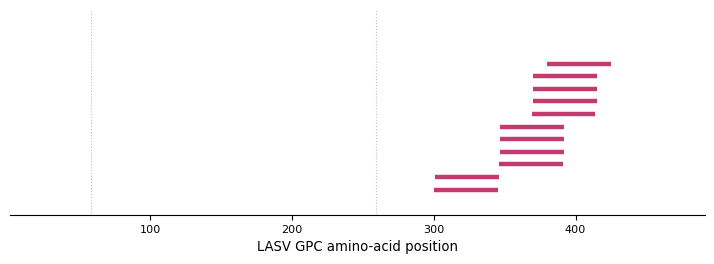

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 2.7))


# domains
for x in [SSP_END, GP1_END]:
    ax.axvline(x, color='0.75', lw=0.8, ls=':')

for i, row in mapped_hits.iterrows():
    y = 0.0 + i * 0.085
    ax.plot(
        [row['full_start'], row['full_end']],
        [y, y],
        color=SURVIVOR_COLOR,
        lw=3.2,
        solid_capstyle='butt'
    )

ax.set_xlim(1, len(gpc_ref))
ax.set_ylim(-0.17, 0.28 + len(mapped_hits)*0.085)
ax.set_xlabel('LASV GPC amino-acid position')
ax.set_yticks([])
ax.spines['left'].set_visible(False)


fig.tight_layout()
fig.savefig(OUTDIR/'Panel_A_GPC_neutralization_hits.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_A_GPC_neutralization_hits.pdf', bbox_inches='tight')
plt.show()


# Panel B — aligned neutralization-associated sequences

This panel can show either LASV-only hits or Mammarenavirus hits if you load a previously generated Mammarenavirus positive-hit table.

By default it uses the LASV hits reconstructed above. To use Mammarenavirus hits, assign a dataframe with columns `sequence`, `delta_median_neut`, and `FDR_screen` to `alignment_hits` before running the mapping cell.


In [6]:
# Default: LASV positive hits.
alignment_hits = positive_hits.copy()

# If you have your Mammarenavirus screen in memory, replace with:
# alignment_hits = mammarenavirus_positive_hits.copy()

alignment_mapped = []
for _, row in alignment_hits.iterrows():
    res = align_full_peptide_to_reference(row['sequence'], gpc_ref, aligner)
    if res is None:
        continue
    alignment_mapped.append({**row.to_dict(), **res})

alignment_mapped = (
    pd.DataFrame(alignment_mapped)
      .sort_values(['full_start','full_end'])
      .reset_index(drop=True)
)

region_start = max(1, int(alignment_mapped['full_start'].min()) - 2)
region_end = min(len(gpc_ref), int(alignment_mapped['full_end'].max()) + 2)
josiah_region = gpc_ref[region_start-1:region_end]

def make_display(seq, full_start, region_start, region_end):
    chars = [' '] * (region_end-region_start+1)
    for i, aa in enumerate(str(seq)):
        pos = int(full_start) + i
        if region_start <= pos <= region_end:
            chars[pos-region_start] = aa
    return ''.join(chars)

def dot_matches(s, ref):
    return ''.join(
        ' ' if aa == ' ' else '.' if aa == raa else aa
        for aa, raa in zip(s, ref)
    )

alignment_mapped['display'] = alignment_mapped.apply(
    lambda r: make_display(
        r['sequence'], r['full_start'], region_start, region_end
    ),
    axis=1
)
alignment_mapped['dots'] = alignment_mapped['display'].apply(
    lambda s: dot_matches(s, josiah_region)
)

print(f'Josiah {region_start}-{region_end}')
print(josiah_region)
for i, row in alignment_mapped.iterrows():
    print(
        f'pep {i+1:>2}  {row["dots"]}  '
        f'ΔNeut={row["delta_median_neut"]:+.1f}  '
        f'FDR={row["FDR_screen"]:.3g}'
    )


Josiah 298-427
VAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTP
pep  1    ..............................................                                                                                    ΔNeut=+20.5  FDR=4.66e-05
pep  2     ............W...................N.............                                                                                   ΔNeut=+20.8  FDR=4.66e-05
pep  3                                                  ............................N.V..KS...........                                      ΔNeut=+19.9  FDR=9.66e-06
pep  4                                                   .............................V..K.............                                     ΔNeut=+21.3  FDR=1.85e-06
pep  5                                                   .............................I..K....R........                                     ΔNeut=+18.4  FDR=9.66e-06
pep  6                  

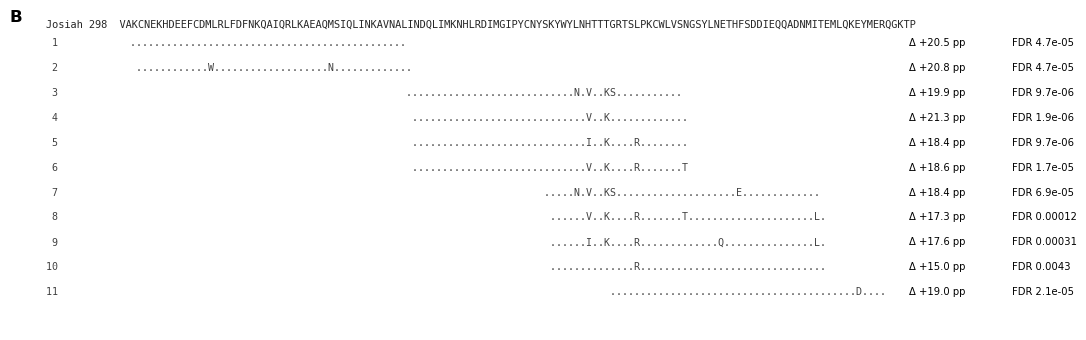

In [7]:
# Publication-style monospaced alignment panel
n = len(alignment_mapped)
fig_h = max(2.8, 0.23*(n+4))
fig, ax = plt.subplots(figsize=(11.0, fig_h))

ax.axis('off')

# reference
ax.text(
    0.0, 1.0,
    f'Josiah {region_start}  {josiah_region}',
    transform=ax.transAxes,
    fontfamily='monospace',
    fontsize=7.4,
    va='top',
    color='0.15'
)

for i, row in alignment_mapped.iterrows():
    y = 0.94 - i*(0.88/max(n,1))
    label = f'{i+1:>2}'
    ax.text(
        0.0, y,
        f'{label}          {row["dots"]}',
        transform=ax.transAxes,
        fontfamily='monospace',
        fontsize=7.2,
        va='top',
        color='0.25'
    )
    ax.text(
        0.84, y,
        f'Δ {row["delta_median_neut"]:+.1f} pp',
        transform=ax.transAxes,
        fontsize=7.2,
        va='top'
    )
    ax.text(
        0.94, y,
        f'FDR {row["FDR_screen"]:.2g}',
        transform=ax.transAxes,
        fontsize=7.2,
        va='top'
    )

ax.text(-0.035, 1.03, 'B', transform=ax.transAxes,
        fontsize=12, fontweight='bold', va='top')

fig.tight_layout()
fig.savefig(OUTDIR/'Panel_B_sequence_alignment.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_B_sequence_alignment.pdf', bbox_inches='tight')
plt.show()


# Panel C — region recognition vs neutralization

Region-positive = survivor recognizes **at least one** significant LASV GPC peptide in the mapped neutralization-associated region.

The panel reports:
- raw participant-level neutralization distributions;
- age/sex/time-adjusted effect;
- secondary GP-ELISA-adjusted effect.

The GP-ELISA adjustment asks whether region recognition carries information beyond overall GP-binding antibody magnitude.


In [8]:
region_peptides = mapped_hits['peptide'].tolist()

g = lasv_neut.loc[lasv_neut['peptide'].isin(region_peptides)].copy()

region_data = (
    g.groupby('individual', as_index=False)
     .agg(
         region_reactive=('reactive','max'),
         Neut_Percent=('Neut_Percent','first'),
         GP_Calc_Conc=('GP_Calc_Conc','first'),
         age_years=('age_years','first'),
         years_since_discharge=('years_since_discharge','first'),
         sex_model=('sex_model','first')
     )
)

region_data['region_reactive'] = region_data['region_reactive'].astype(int)
region_data['sex_model'] = region_data['sex_model'].astype(object)
region_data['GP_log1p'] = np.log1p(
    pd.to_numeric(region_data['GP_Calc_Conc'], errors='coerce')
)

pos = region_data.loc[region_data['region_reactive']==1, 'Neut_Percent'].dropna()
neg = region_data.loc[region_data['region_reactive']==0, 'Neut_Percent'].dropna()

_, p_raw = mannwhitneyu(pos, neg, alternative='two-sided')

tmpA = region_data[
    ['Neut_Percent','region_reactive','age_years',
     'sex_model','years_since_discharge']
].dropna().copy()

mA = smf.ols(
    'Neut_Percent ~ region_reactive + age_years + C(sex_model) + years_since_discharge',
    data=tmpA
).fit(cov_type='HC3')

betaA = mA.params['region_reactive']
ciA = mA.conf_int().loc['region_reactive']
pA = mA.pvalues['region_reactive']

tmpB = region_data[
    ['Neut_Percent','region_reactive','GP_log1p','age_years',
     'sex_model','years_since_discharge']
].dropna().copy()

mB = smf.ols(
    'Neut_Percent ~ region_reactive + GP_log1p + age_years + C(sex_model) + years_since_discharge',
    data=tmpB
).fit(cov_type='HC3')

betaB = mB.params['region_reactive']
ciB = mB.conf_int().loc['region_reactive']
pB = mB.pvalues['region_reactive']

print('Region positive:', len(pos), 'Region negative:', len(neg))
print('Median +:', pos.median(), 'Median -:', neg.median())
print('Raw MW p:', p_raw)
print('Adjusted:', betaA, tuple(ciA), pA)
print('GP-adjusted:', betaB, tuple(ciB), pB)


Region positive: 66 Region negative: 52
Median +: 83.922969285 Median -: 60.256990314999996
Raw MW p: 4.428131284382316e-07
Adjusted: 22.782465492375795 (10.895882442256893, 34.6690485424947) 0.0001722563355054344
GP-adjusted: 18.823161668911226 (7.800686581143982, 29.84563675667847) 0.0008167798189773485


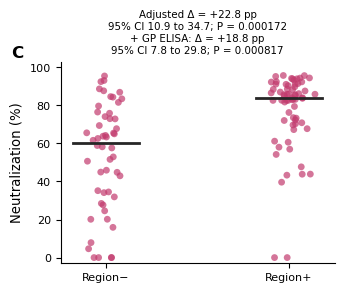

In [9]:
# Deterministic jitter for display only
rng = np.random.default_rng(11)

fig, ax = plt.subplots(figsize=(3.5, 3.5))

for x, vals in [(0, neg), (1, pos)]:
    jitter = rng.normal(0, 0.055, len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=24,
        alpha=0.70,
        color=SURVIVOR_COLOR,
        edgecolor='none'
    )

    med = np.median(vals)
    ax.plot([x-0.18, x+0.18], [med, med], color='0.15', lw=2)

ax.set_xticks([0,1])
ax.set_xticklabels(['Region−','Region+'])
ax.set_ylabel('Neutralization (%)')
ax.set_ylim(-3, 103)

annotation = (
    f'Adjusted Δ = {betaA:+.1f} pp\n'
    f'95% CI {ciA.iloc[0]:.1f} to {ciA.iloc[1]:.1f}; P = {pA:.3g}\n'
    f'+ GP ELISA: Δ = {betaB:+.1f} pp\n'
    f'95% CI {ciB.iloc[0]:.1f} to {ciB.iloc[1]:.1f}; P = {pB:.3g}'
)

ax.text(
    0.5, 1.03, annotation,
    transform=ax.transAxes,
    ha='center', va='bottom',
    fontsize=7.4,
    linespacing=1.25
)

ax.text(-0.18, 1.08, 'C', transform=ax.transAxes,
        fontsize=12, fontweight='bold', va='top')

fig.tight_layout(rect=[0,0,1,0.86])
fig.savefig(OUTDIR/'Panel_C_region_neutralization.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_C_region_neutralization.pdf', bbox_inches='tight')
plt.show()


# Panel D — structural / neutralizing-antibody footprint annotation

This panel intentionally does **not** hard-code literature residues.

Populate `STRUCTURAL_ANNOTATIONS` only with residues/ranges supported by a cited structural, escape, or mutagenesis source. This prevents the figure from implying residue-level evidence that the PhIP-Seq data do not establish.

Suggested columns:
- `label`: mAb or epitope name
- `start`, `end`: Josiah residue/range
- `evidence`: `contact`, `escape`, `mutagenesis`, etc.
- `citation`: DOI/PMID or short source label

Once populated, the plot overlays those annotations with the PhIP neutralization-associated interval.


In [10]:
# Fill this after systematic literature/structure review.
# Example FORMAT ONLY — do not treat these as real residues.
STRUCTURAL_ANNOTATIONS = pd.DataFrame(
    columns=['label','start','end','evidence','citation']
)

# Neutralization-associated interval from significant peptide mapping
NEUT_START = int(mapped_hits['full_start'].min())
NEUT_END = int(mapped_hits['full_end'].max())

print('PhIP neutralization-associated interval:', NEUT_START, '-', NEUT_END)
display(STRUCTURAL_ANNOTATIONS)


PhIP neutralization-associated interval: 300 - 425


,label,start,end,evidence,citation


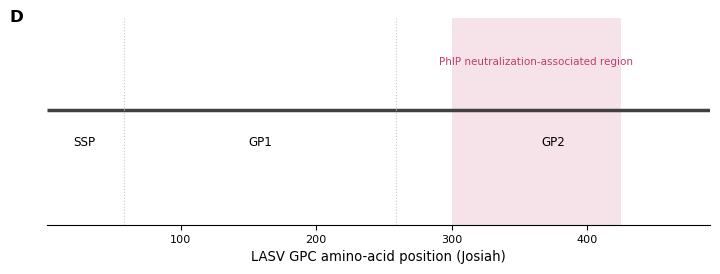

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 2.8))

# backbone
ax.hlines(0, 1, len(gpc_ref), color='0.25', lw=2.5)

# domains
for x in [SSP_END, GP1_END]:
    ax.axvline(x, color='0.78', lw=0.8, ls=':')

# PhIP region
ax.axvspan(
    NEUT_START, NEUT_END,
    color=SURVIVOR_COLOR,
    alpha=0.14,
    linewidth=0
)
ax.text(
    (NEUT_START+NEUT_END)/2,
    0.13,
    'PhIP neutralization-associated region',
    ha='center', va='bottom',
    fontsize=7.5,
    color=SURVIVOR_COLOR
)

# structural annotations
if len(STRUCTURAL_ANNOTATIONS):
    for i, row in STRUCTURAL_ANNOTATIONS.reset_index(drop=True).iterrows():
        y = -0.15 - i*0.12
        ax.plot(
            [row['start'], row['end']],
            [y,y],
            lw=4,
            solid_capstyle='butt',
            color=BLUE
        )
        ax.text(
            row['end']+4, y,
            f"{row['label']} ({row['evidence']})",
            va='center', fontsize=7.2
        )

ax.text(SSP_END/2, -0.08, 'SSP', ha='center', va='top')
ax.text((SSP_END+GP1_END)/2, -0.08, 'GP1', ha='center', va='top')
ax.text((GP1_END+len(gpc_ref))/2, -0.08, 'GP2', ha='center', va='top')

ax.set_xlim(1, len(gpc_ref))
ax.set_ylim(
    -0.35-max(0,len(STRUCTURAL_ANNOTATIONS)-1)*0.12,
    0.28
)
ax.set_xlabel('LASV GPC amino-acid position (Josiah)')
ax.set_yticks([])
ax.spines['left'].set_visible(False)

ax.text(-0.055, 1.04, 'D', transform=ax.transAxes,
        fontsize=12, fontweight='bold', va='top')

fig.tight_layout()
fig.savefig(OUTDIR/'Panel_D_structural_annotation.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'Panel_D_structural_annotation.pdf', bbox_inches='tight')
plt.show()


# Optional — assemble A/C/D-style composite after finalizing Panel B

For manuscript production, vector panels are often easiest to assemble in Illustrator/Inkscape/Affinity Designer. The notebook exports every panel as both SVG and PDF with editable text.

Recommended final layout:

```
A  GPC map of significant peptide hits
B  sequence alignment (wide)
C  region− vs region+ neutralization
D  structural footprint / known nAb annotation
```

Panel B will likely need the most horizontal space.


## Figure-legend draft

**Neutralization-associated LASV glycoprotein antibody specificity.**  
**(A)** LASV GPC peptides whose recognition was significantly associated with higher serum neutralization after Benjamini–Hochberg correction, mapped to the LASV Josiah GPC reference. Full peptide-tile lengths are shown.  
**(B)** Coordinate-aligned sequences of neutralization-associated GPC peptides relative to Josiah; dots indicate identity to the reference and letters indicate amino-acid substitutions. Δ denotes the difference in median neutralization between peptide-reactive and peptide-nonreactive survivors.  
**(C)** Serum neutralization among survivors with or without recognition of the neutralization-associated GPC region. Horizontal bars denote medians. Adjusted effects were estimated by multivariable linear regression including age, sex, and years since discharge; a secondary model additionally adjusted for log-transformed GP ELISA concentration.  
**(D)** Location of the PhIP-Seq neutralization-associated region relative to literature-supported neutralizing-antibody structural, escape, or mutagenesis footprints. Structural annotations should be added only after source verification.
